In [62]:
import importlib
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import SMA_iteration2 as SMA_it2
import SMA_iteration1 as SMA_it1
importlib.reload(SMA_it2)
import SMA_test1 as SMA_t1
importlib.reload(SMA_t1)
import SMA_iteration0 as SMA_it0
importlib.reload(SMA_it0)
import SMA_test2 as SMA_t2
importlib.reload(SMA_t2)
import SMA_test3 as SMA_t3
importlib.reload(SMA_t3)
import SMA_test4 as SMA_t4
importlib.reload(SMA_t4)

<module 'SMA_test4' from 'C:\\Users\\Aakash\\Documents\\anaconda\\PROJECT1\\INTC\\Analysis\\SMA_test4.py'>

[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

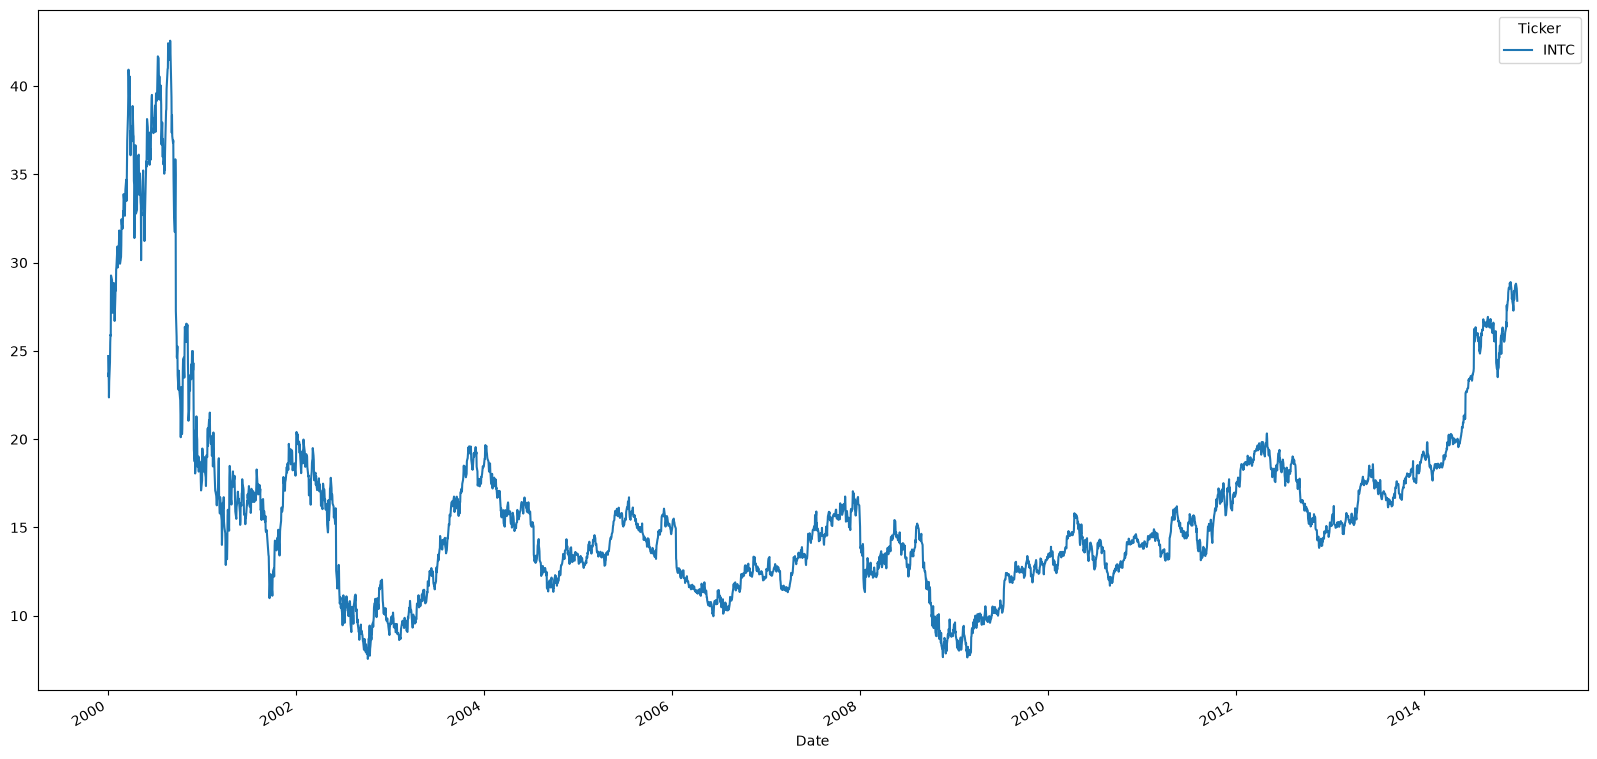

In [20]:
data=yf.download("INTC",start="2000-01-01",end="2015-01-01")
data.Close.plot(figsize=(20,10))

[*********************100%***********************]  1 of 1 completed


(np.float64(0.37008824174577604), np.float64(0.15359597229377744), np.float64(-0.467741))


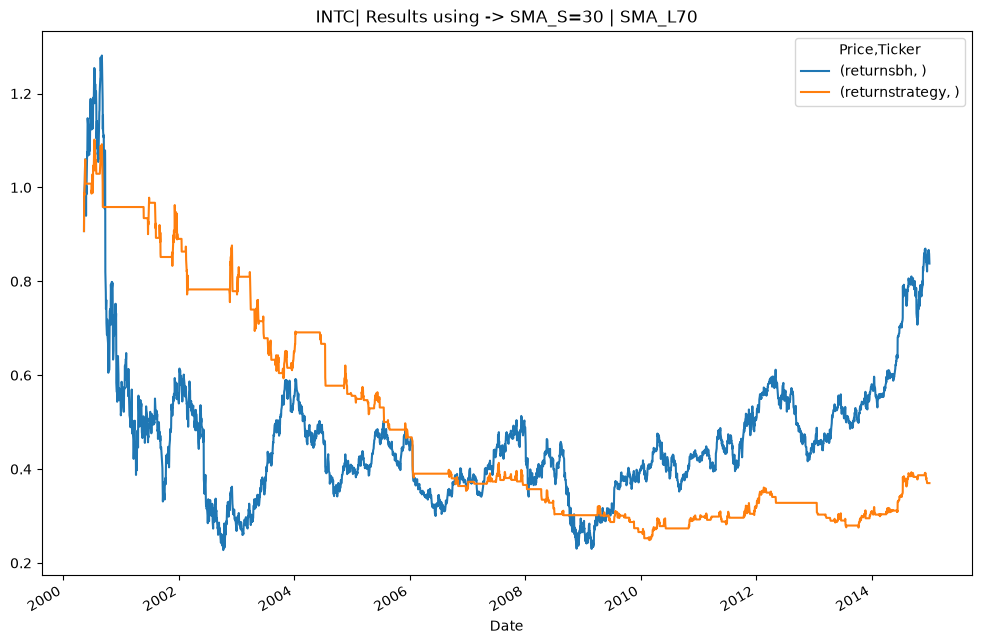

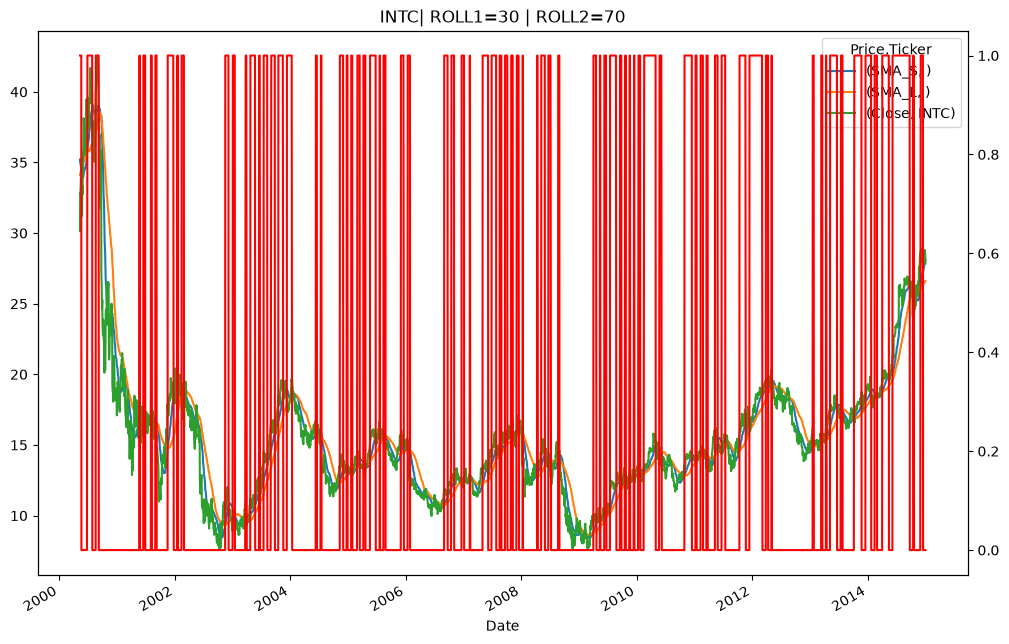

In [21]:

test1=SMA_it2.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20,15)

print(test1.test_result())
test1.plot_results()
test1.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.9174556618383691), np.float64(0.22852067395518455), np.float64(0.079626))


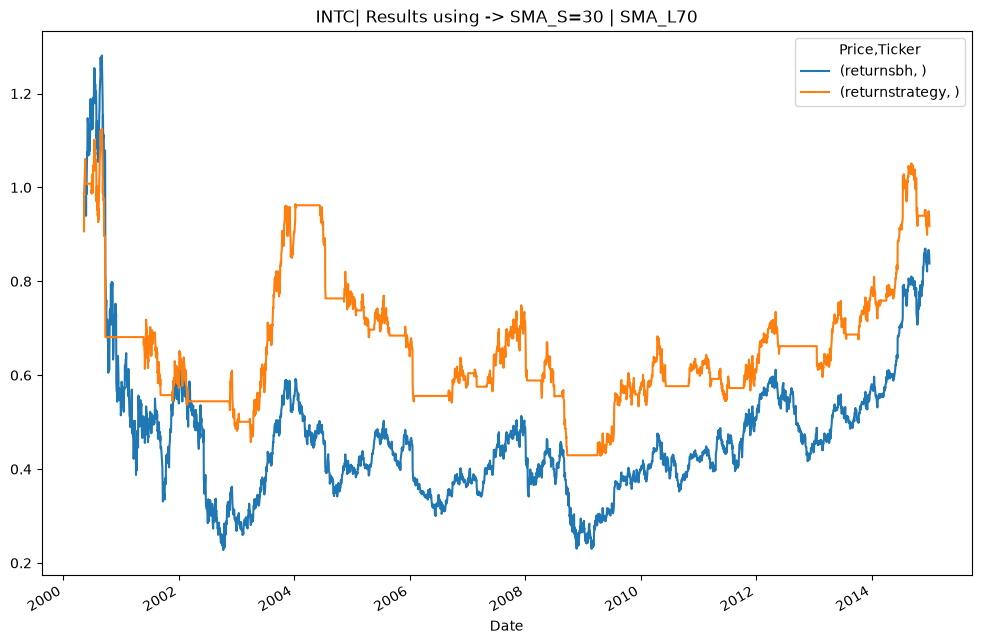

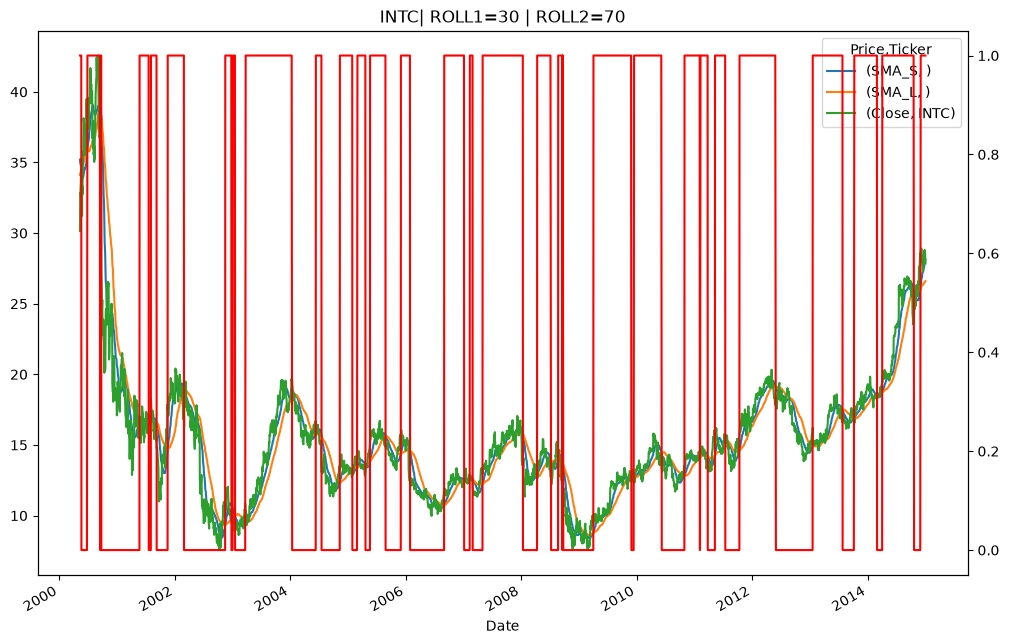

In [22]:
test2=SMA_it1.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20)

print(test2.test_result())
test2.plot_results()
test2.roll_graph()

[*********************100%***********************]  1 of 1 completed


hello
(np.float64(0.996616074566153), np.float64(0.3964139767844668), np.float64(0.24711))


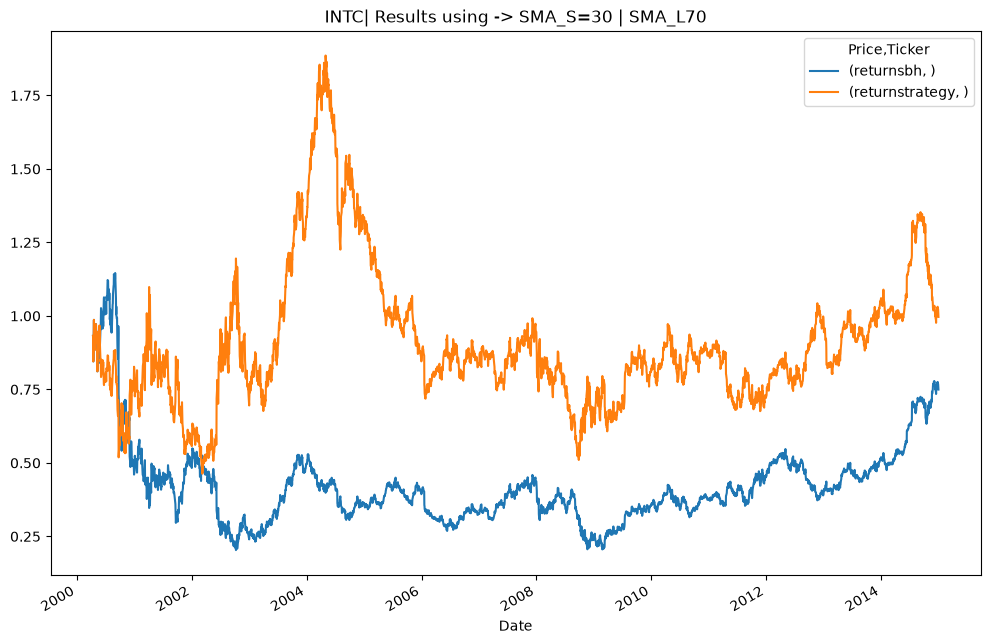

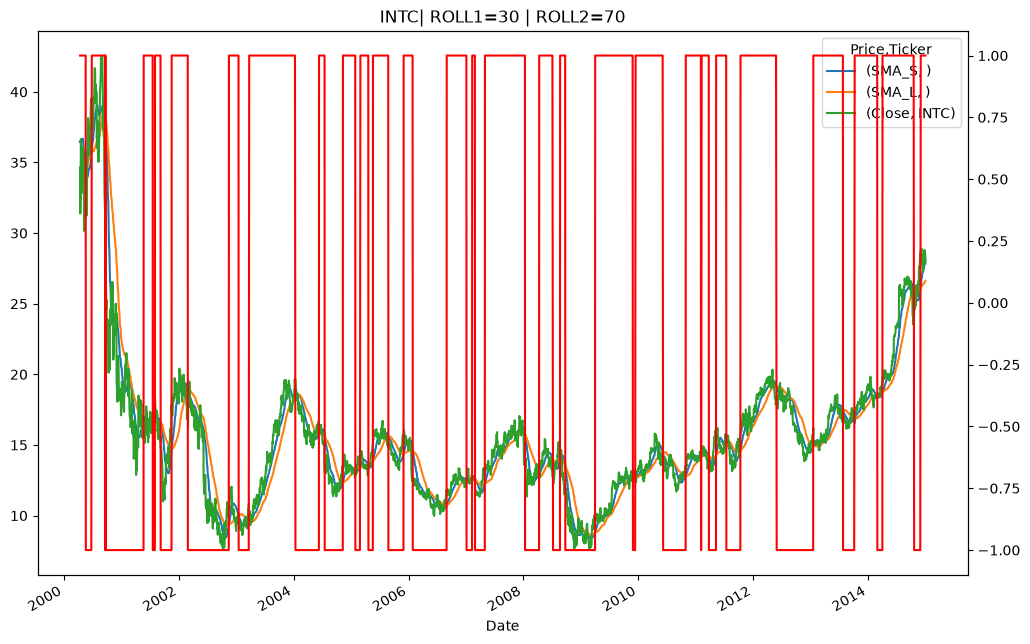

In [27]:
test3=SMA_it0.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01"
                           )

print(test3.test_result())
test3.plot_results()
test3.roll_graph()

In [28]:
# so apparently out strategy and exits are the one making most loses infact if simple SMA strategy is followed it almost gives 1 return
# also we are keeping out of market for very very large periods due to only having positions as 0 and 1 
# till now the examples never had much of gain to hold negative position but now it does 
# hmm so lets see our iteration 2 and iteration 0 for some specific 3 to 4 years to analyse any indicators and where we go wrong 


[*********************100%***********************]  1 of 1 completed


(np.float64(0.6486921369085645), np.float64(0.19281195058338377), np.float64(0.094691))


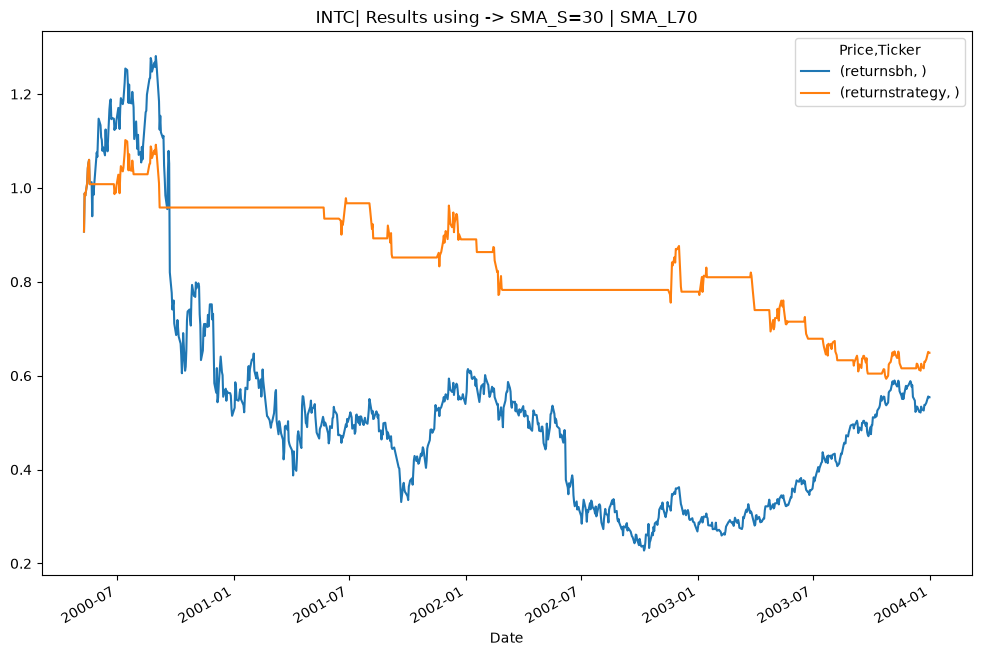

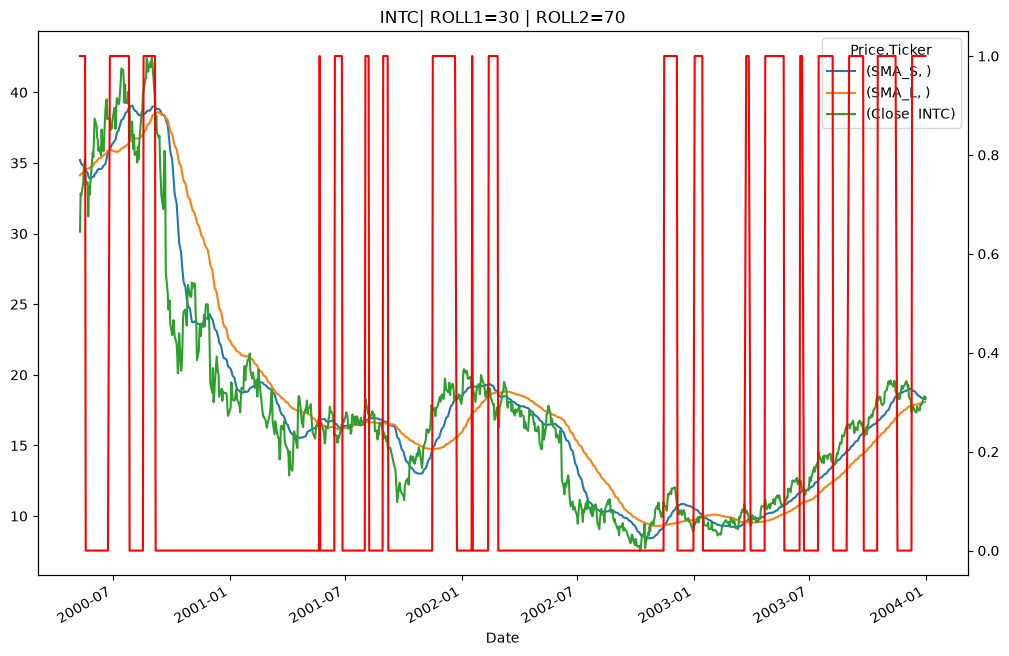

In [29]:

test1a=SMA_it2.SMABacktester("INTC",30,70,"2000-01-01","2004-01-01",20,15)

print(test1a.test_result())
test1a.plot_results()
test1a.roll_graph()

[*********************100%***********************]  1 of 1 completed


hello
(np.float64(1.335154975628277), np.float64(0.6017734481878999), np.float64(0.839556))


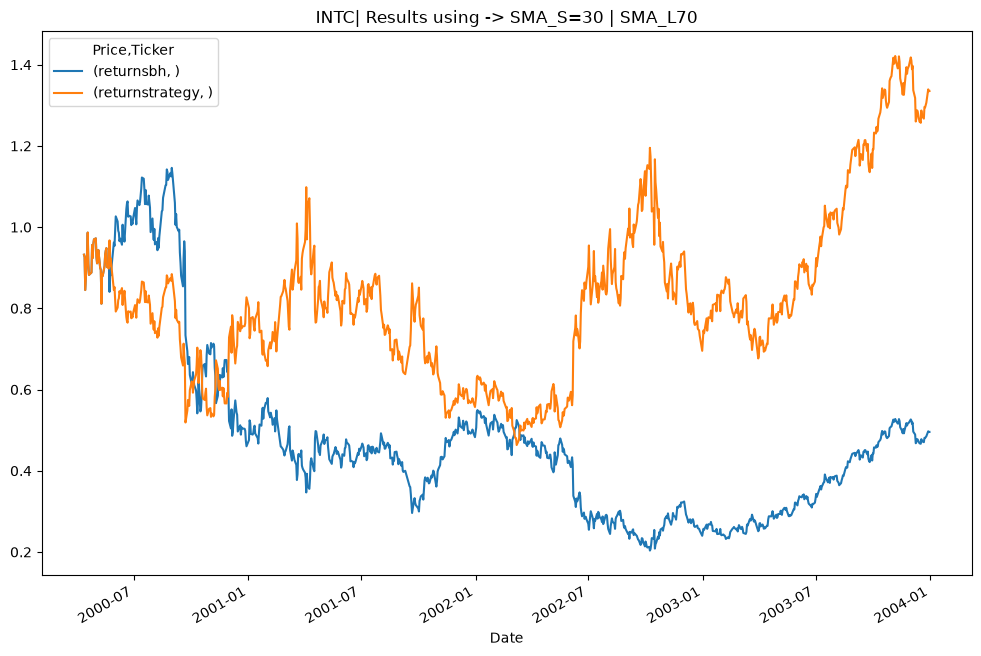

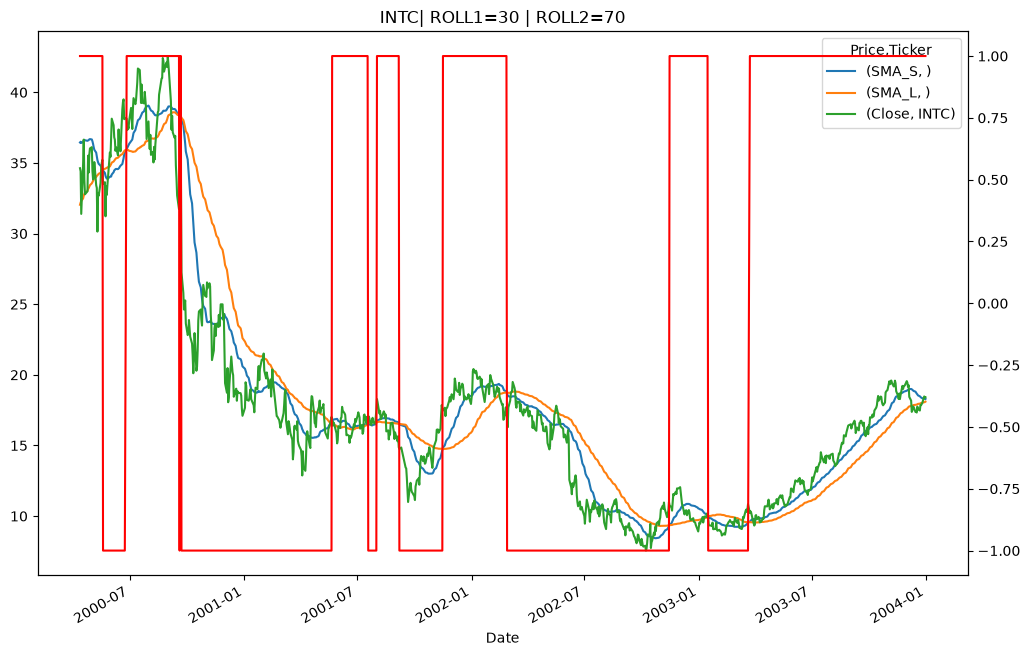

In [30]:
test3a=SMA_it0.SMABacktester("INTC",30,70,"2000-01-01","2004-01-01"
                           )

print(test3a.test_result())
test3a.plot_results()
test3a.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.8417598230440395), np.float64(0.5376317105044891), np.float64(0.287759))


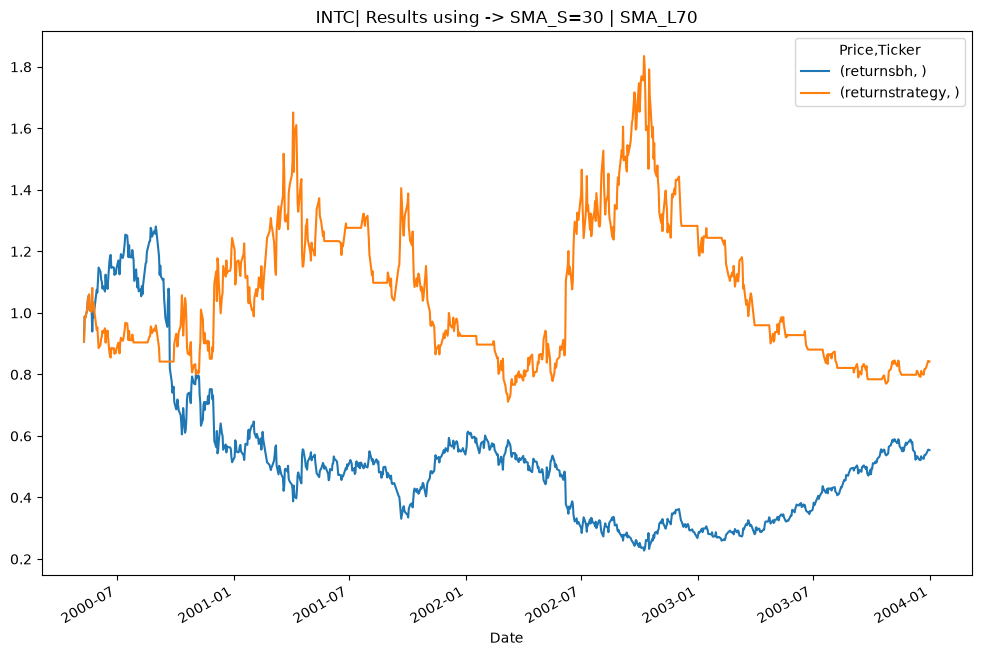

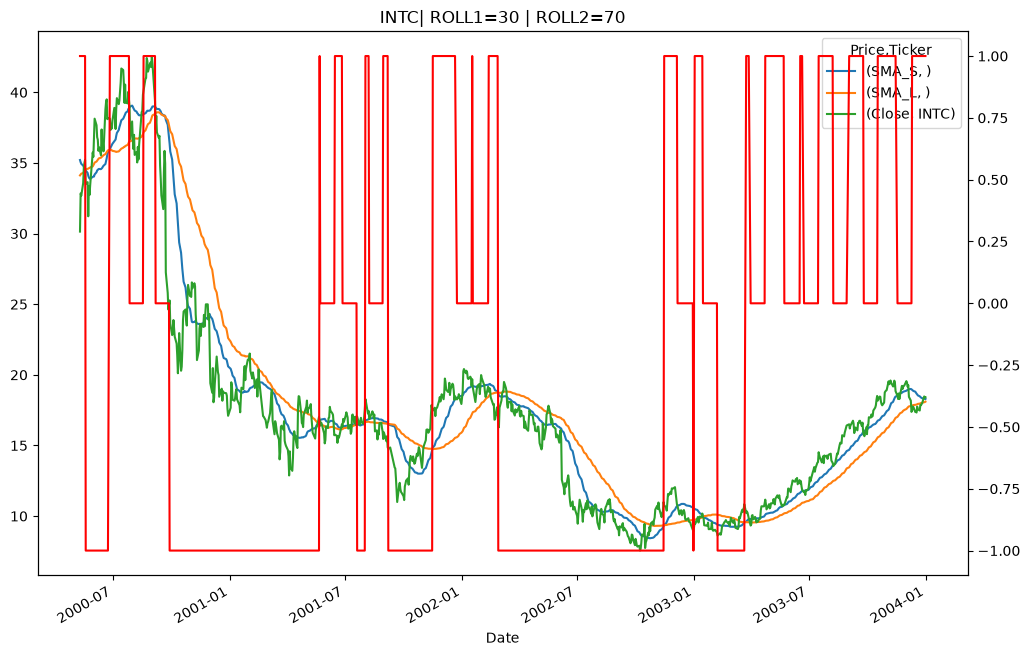

In [34]:
# we see profit with normal SMA and loss with our modified means means our indicators are bringing worst of each other 
#also normal SMA has -1 postion instead of 0 so lets add -1 in iteration 2 as well 
# so test1 SMA has that 
test4a=SMA_t1.SMABacktester("INTC",30,70,"2000-01-01","2004-01-01",20,15
                           )

print(test4a.test_result())
test4a.plot_results()
test4a.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.3385961531825435), np.float64(0.3516885024951141), np.float64(-0.499233))


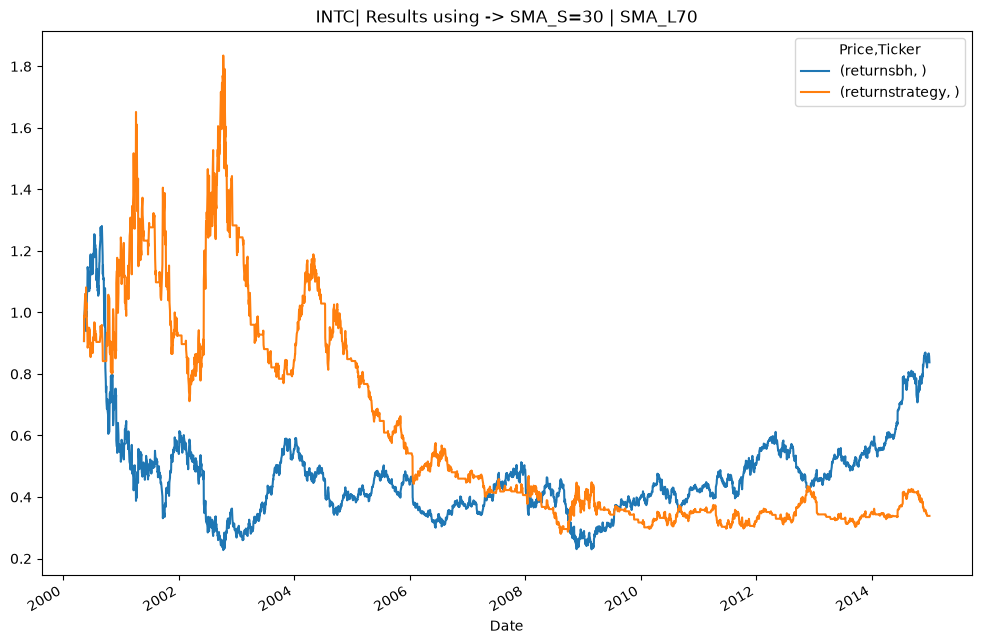

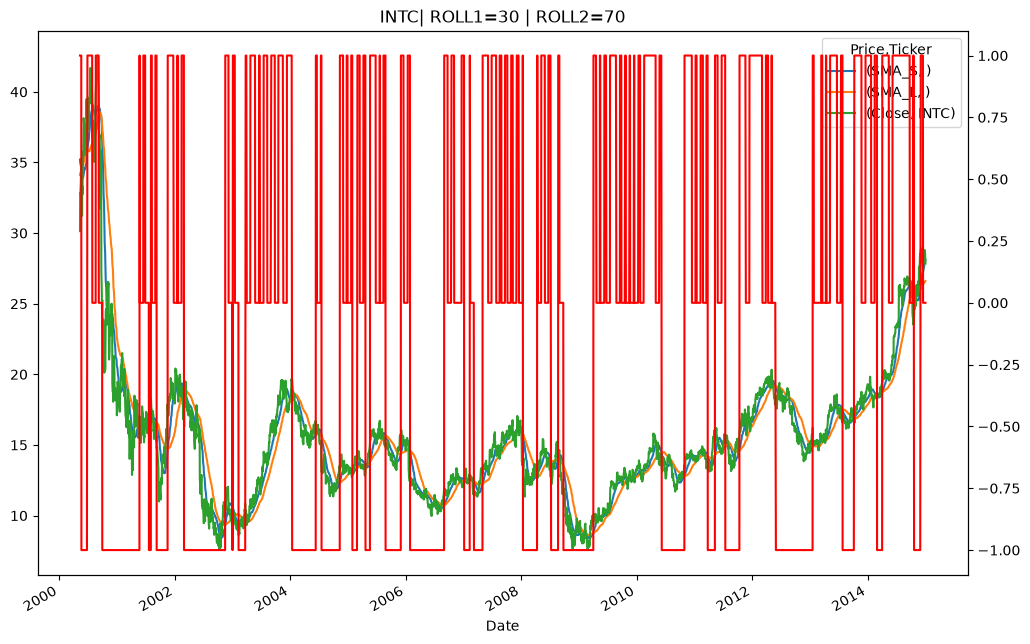

In [35]:
test4=SMA_t1.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20,15
                           )

print(test4.test_result())
test4.plot_results()
test4.roll_graph()

In [36]:
# oh my god this has to be the wrost result ever gotten with the rule i proposed 
# 1) the downwards profits are not being reailsed and 
# 2) cooldown period of 15 days when moving up steeply !
# my current -1 when any other case than both sma_S>L and going steep down high_20 one 
# what instead should have been ok have 1 position in sma_s>sma_l one and high_20 hasnt fallen more than 20 percent ok!
# when do you want to stay out of market  ? 
# and when you think it is good to sell and have -1 position !
# lets look at that !


[*********************100%***********************]  1 of 1 completed


(np.float64(0.8417598230440395), np.float64(0.5376317105044891), np.float64(0.287759))


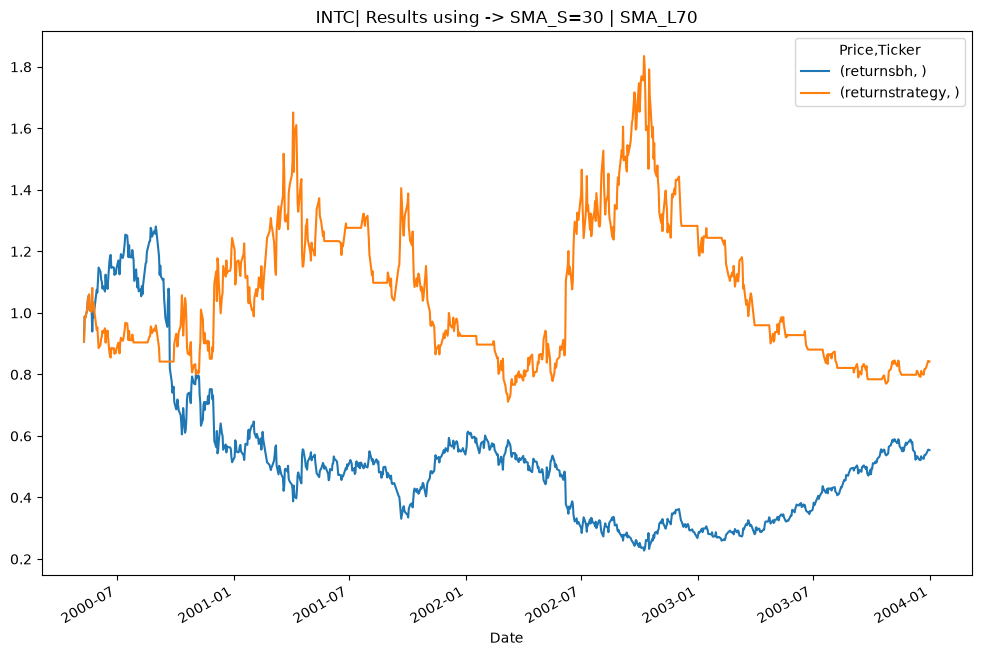

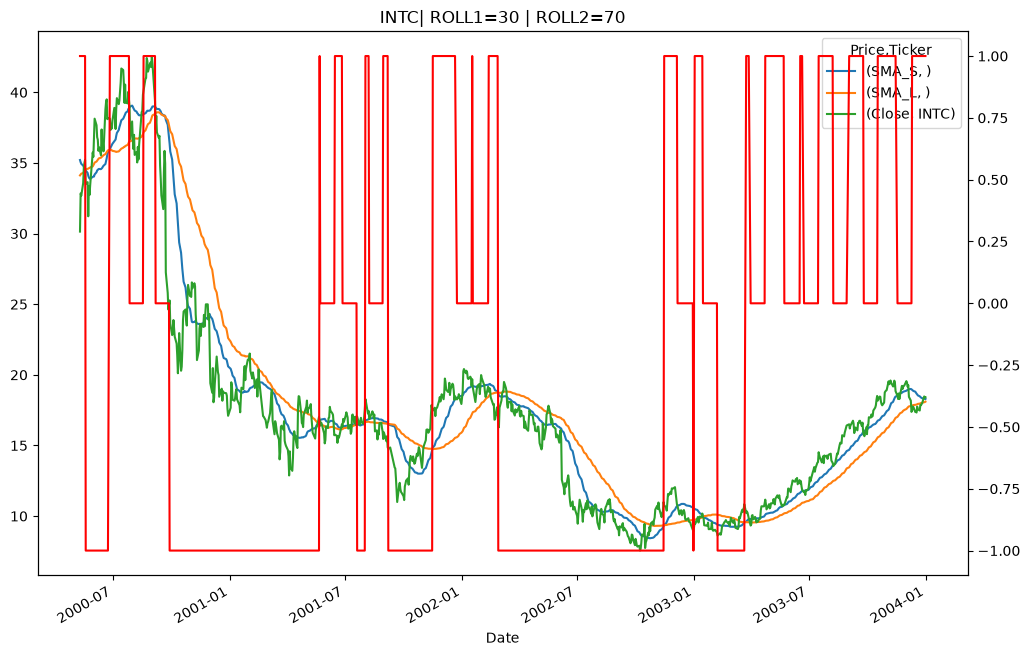

In [37]:

test4a=SMA_t1.SMABacktester("INTC",30,70,"2000-01-01","2004-01-01",20,15
                           )

print(test4a.test_result())
test4a.plot_results()
test4a.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.3530934461735028), np.float64(0.22517545971354663), np.float64(-0.709373))


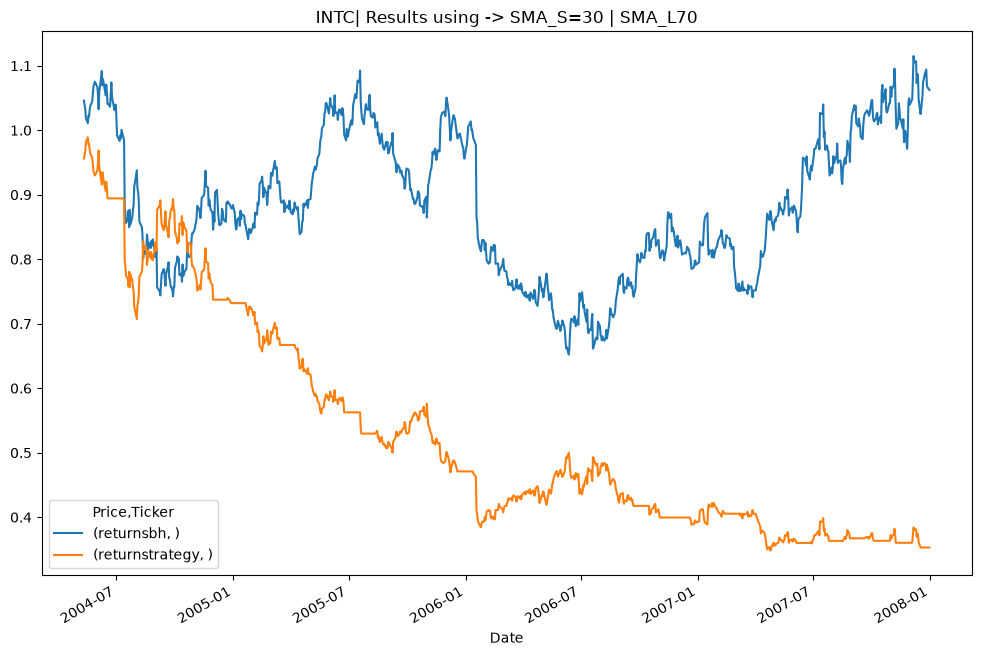

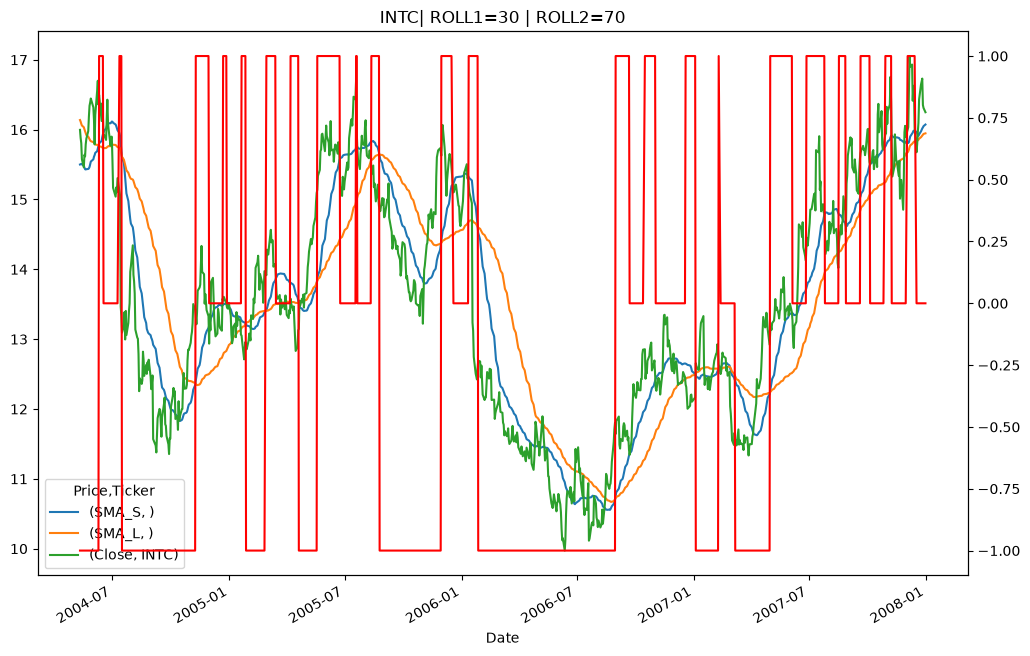

In [38]:

test4b=SMA_t1.SMABacktester("INTC",30,70,"2004-01-01","2008-01-01",20,15
                           )

print(test4b.test_result())
test4b.plot_results()
test4b.roll_graph()

In [41]:
# clearly thsese 4 years hacve the most harm so our current indicator problems are well disguised in these 
# so so we very very well notice that we want to sell when downstream starts and have a non neg position before 
# an easy theory to test will be have -1 in opposites of 1 so if sma_s<sma_l and low_20 into (X percent increase )>=Current then only -1 
# also cooldown period can be introduced after wards

[*********************100%***********************]  1 of 1 completed


(np.float64(0.3530934461735028), np.float64(0.22517545971354663), np.float64(-0.709373))


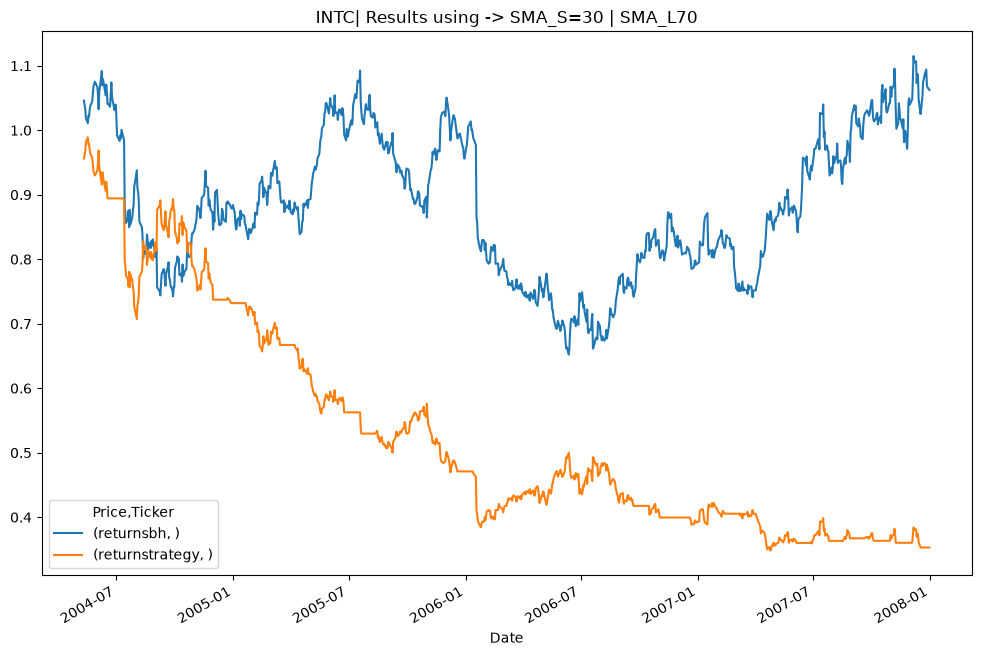

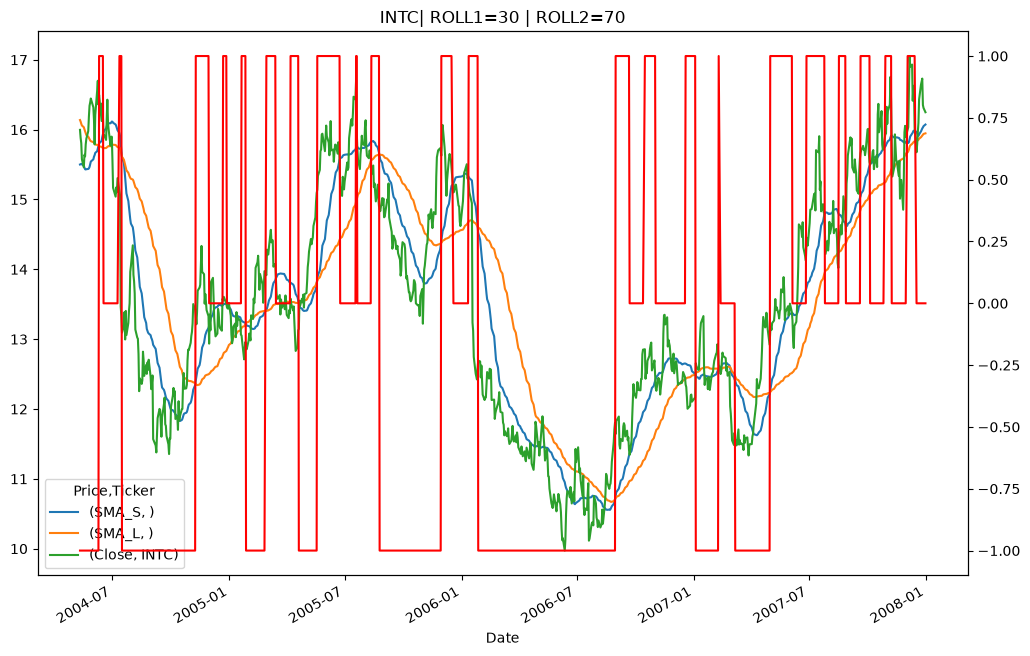

In [46]:

test5b=SMA_t2.SMABacktester("INTC",30,70,"2004-01-01","2008-01-01",20,15
                           )

print(test5b.test_result())
test5b.plot_results()
test5b.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.7712745550617294), np.float64(0.239447297734283), np.float64(-0.03566))


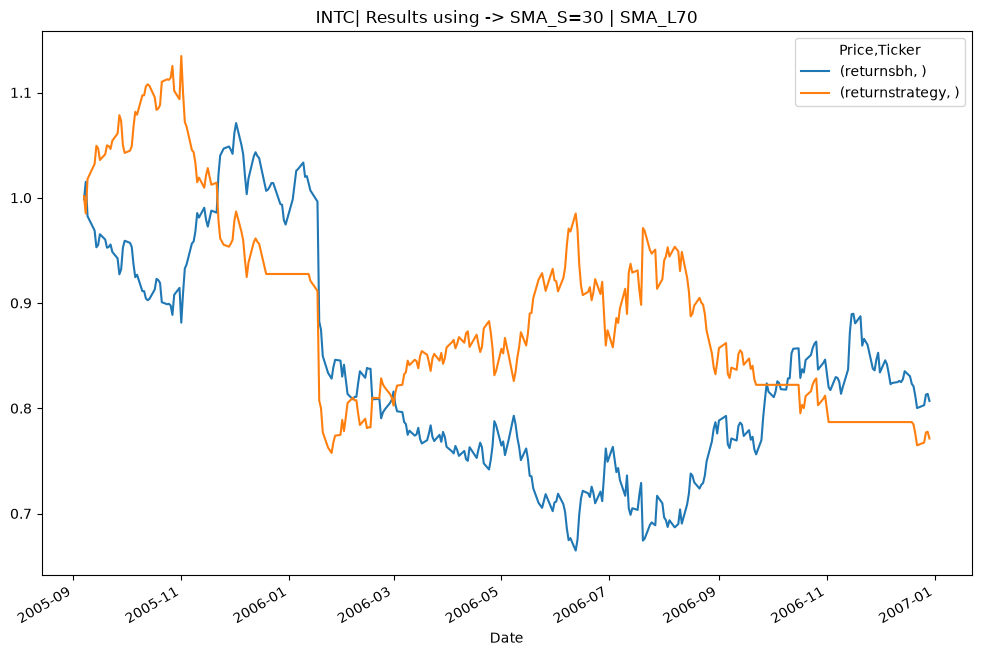

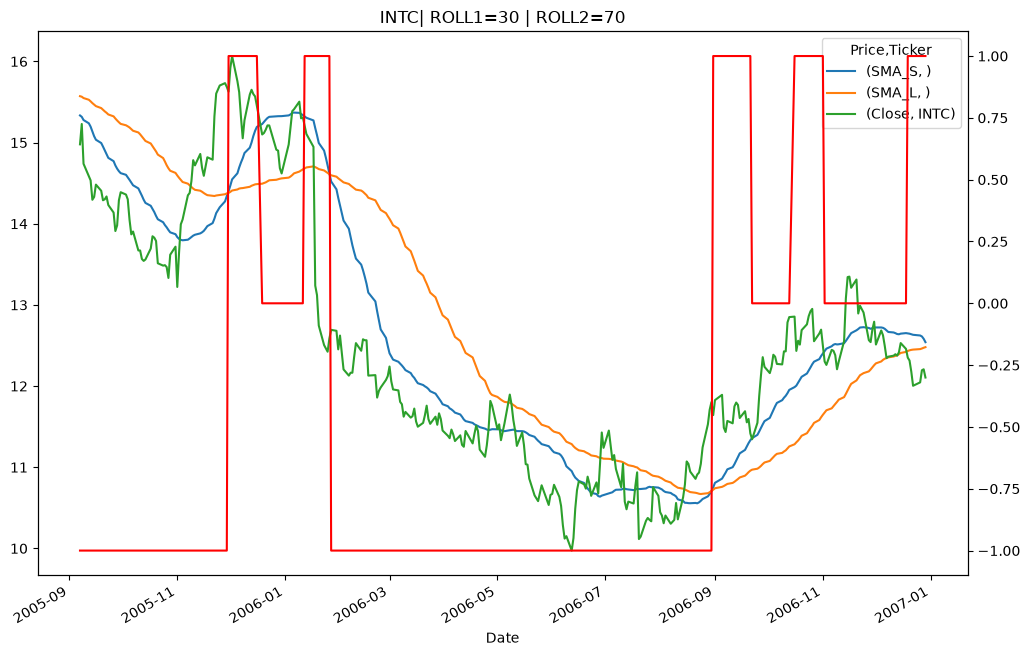

In [54]:

test5c=SMA_t2.SMABacktester("INTC",30,70,"2005-05-01","2007-01-01",20,15
                           )

print(test5c.test_result())
test5c.plot_results()
test5c.roll_graph()

In [55]:
#ok ok lets see where is this all coming from first trade i had to buy back at low whoese signal of up wast enough i guess

#hypothesis1 from above to below if the current trade intersect then upward going and have that cool down thing again

# now trade 2 is also bad but we cant do much ig as let it be an outlier for now as it follows position 1 conditions !
# i mean rest of data to notice is that it happens to be a bad example in general i think

#hypothesis2 and observation
    # a major problem 2006-09 and 2006-11  period suffered because of my intersection of sma_s with with current price which can also mean temporary disallignment
    # not for good tradees but but ended up closing bad trades so the thing is i told that indicator indepented with high_20 indicator 
    # but ig combined with it it would eliminate this but instead of high_20 the percent would be 10 or X/2!


In [ ]:
#test 3 one only focuses on hypothesis 2 !

[*********************100%***********************]  1 of 1 completed


(np.float64(0.8477556287368402), np.float64(0.26013738316306506), np.float64(0.006448))


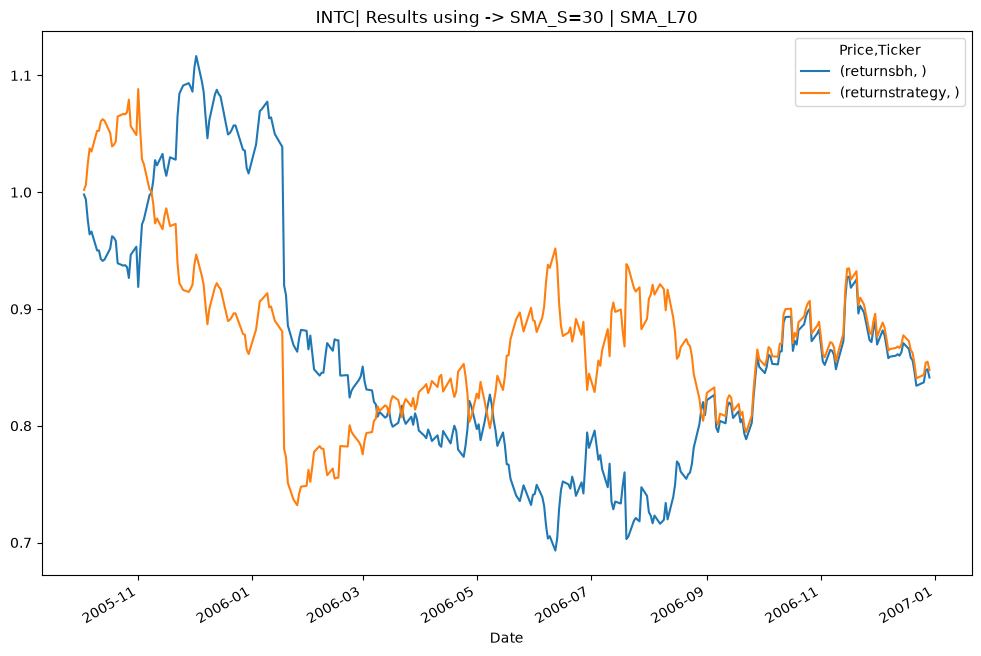

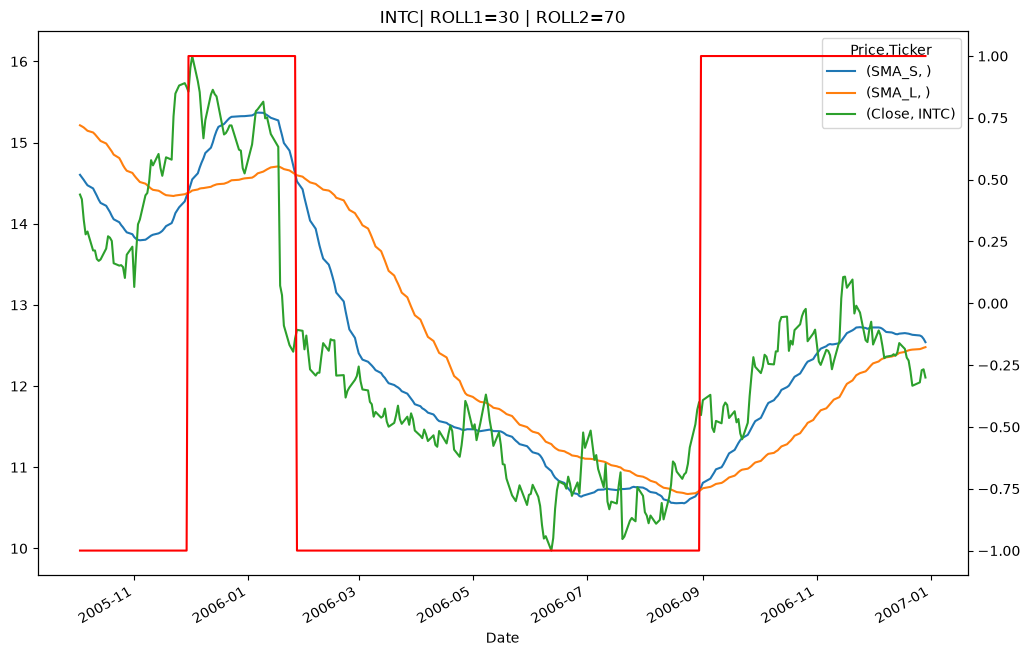

In [58]:
importlib.reload(SMA_t3)
test6c=SMA_t3.SMABacktester("INTC",30,70,"2005-05-01","2007-01-01",20,15
                           )

print(test6c.test_result())
test6c.plot_results()
test6c.roll_graph()

In [ ]:
##ok ok there was that was much much better hypothesis on this data fits!
# lets just try on full

[*********************100%***********************]  1 of 1 completed


(np.float64(0.8358873094699651), np.float64(0.3650657615392336), np.float64(0.096812))


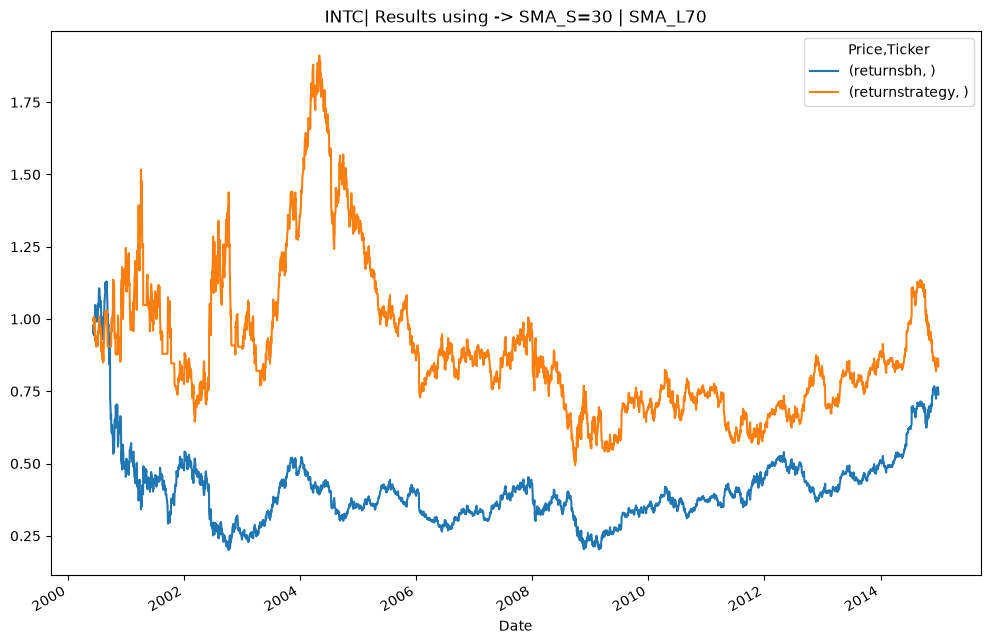

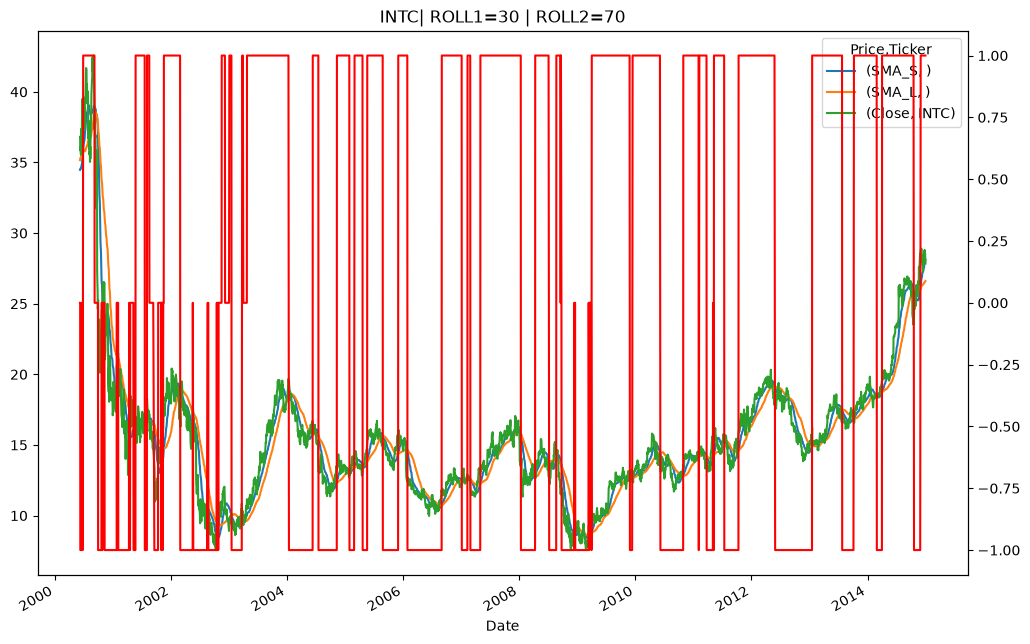

In [59]:
importlib.reload(SMA_t3)
test6=SMA_t3.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20,15
                           )

print(test6.test_result())
test6.plot_results()
test6.roll_graph()

In [60]:
##ok still in loss but we know hypothesis 2 helps alot !

# hypothesis 1 was ->
    #hypothesis1 when going down from above to below if the current trade intersect then upward going and have that cool down thing again


[*********************100%***********************]  1 of 1 completed


(np.float64(0.8477556287368402), np.float64(0.26013738316306506), np.float64(0.006448))


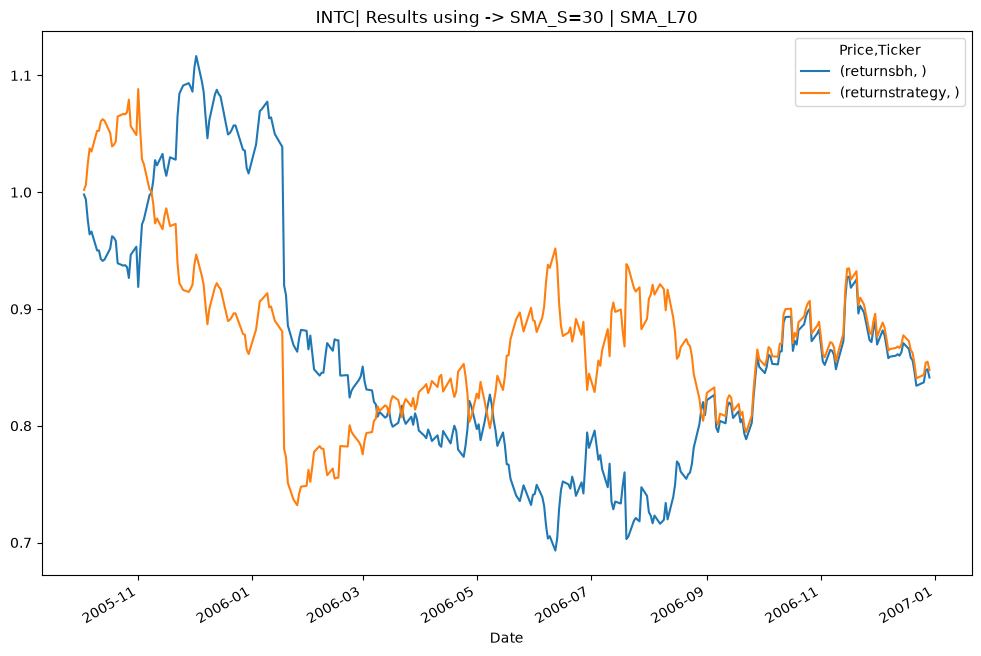

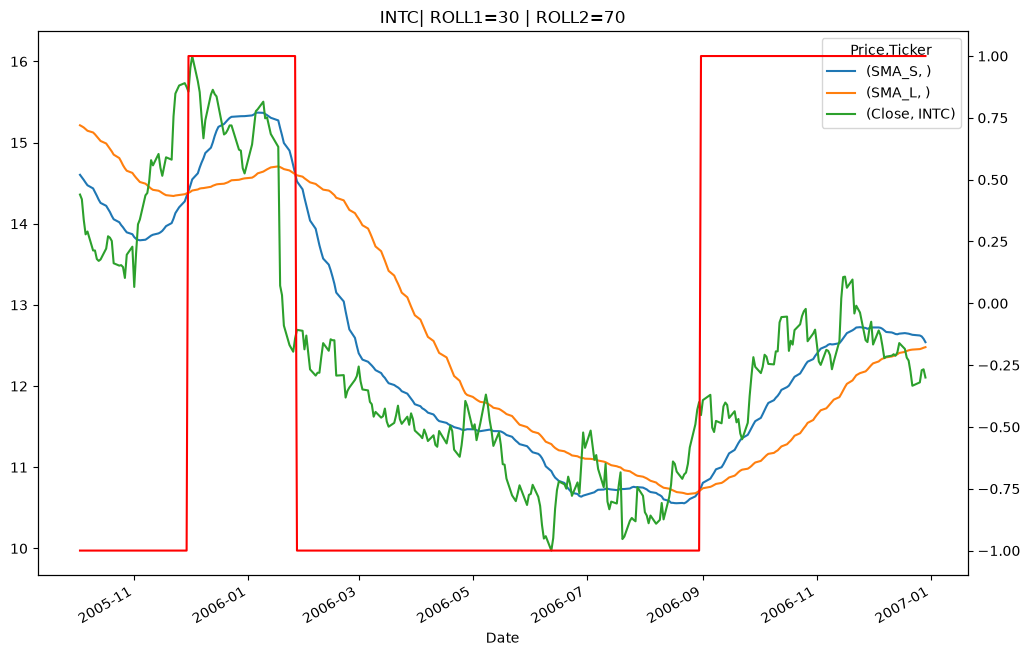

In [61]:
importlib.reload(SMA_t3)
test6c=SMA_t3.SMABacktester("INTC",30,70,"2005-05-01","2007-01-01",20,15
                           )

print(test6c.test_result())
test6c.plot_results()
test6c.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.8477556287368402), np.float64(0.26013738316306506), np.float64(0.006448))


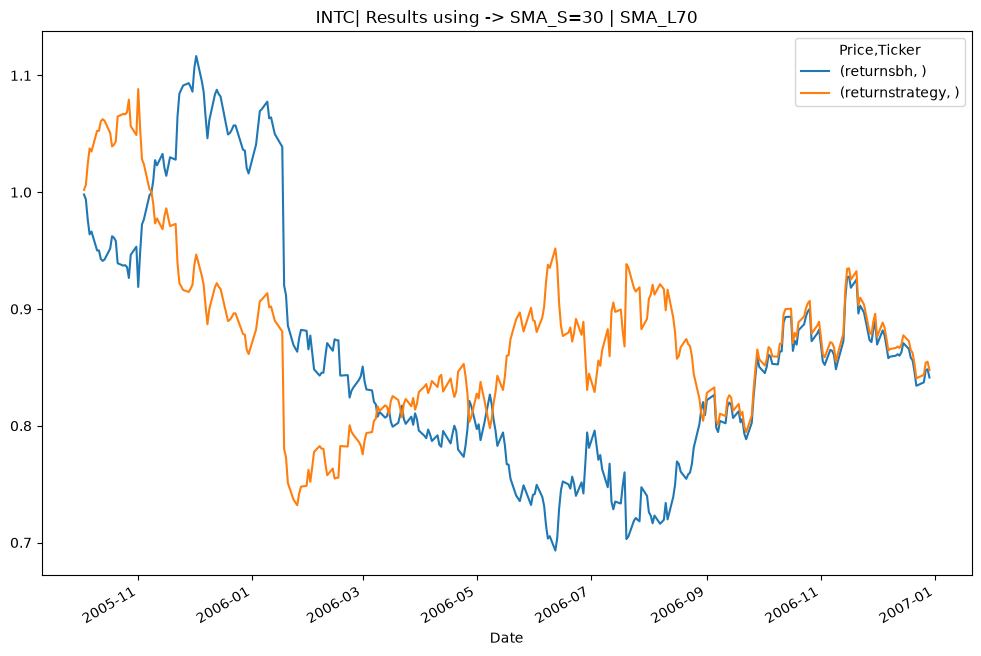

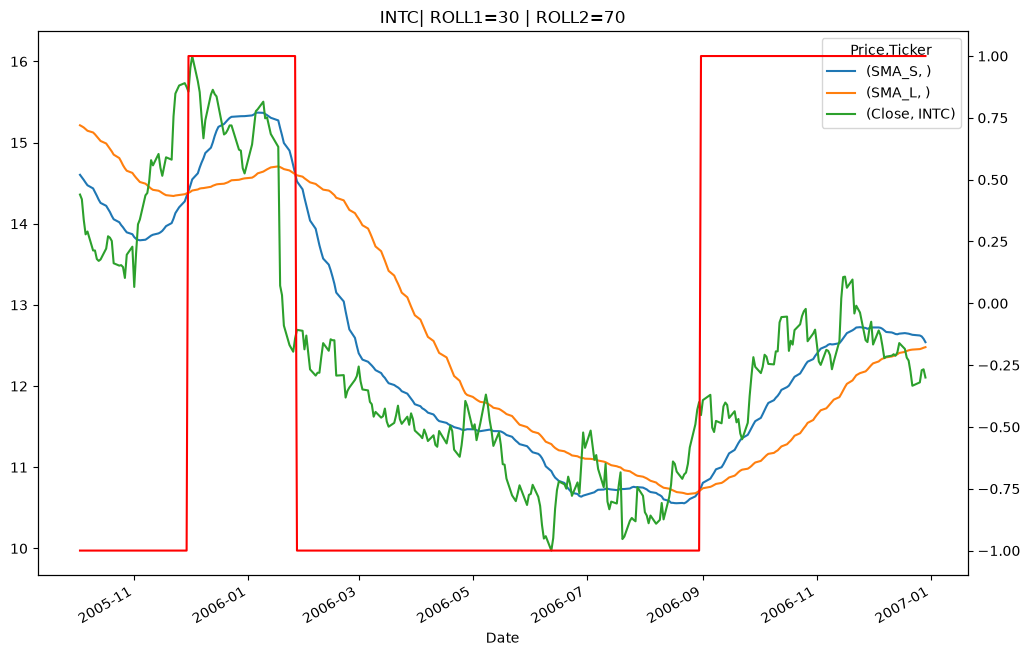

In [64]:
#ok test 4 ready with hypothesis 1 as well 
import SMA_test4 as SMA_t4
importlib.reload(SMA_t4)
test7c=SMA_t4.SMABacktester("INTC",30,70,"2005-05-01","2007-01-01",20,15
                           )

print(test7c.test_result())
test7c.plot_results()
test7c.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(1.297064901671211), np.float64(0.33201524593037895), np.float64(0.55799))


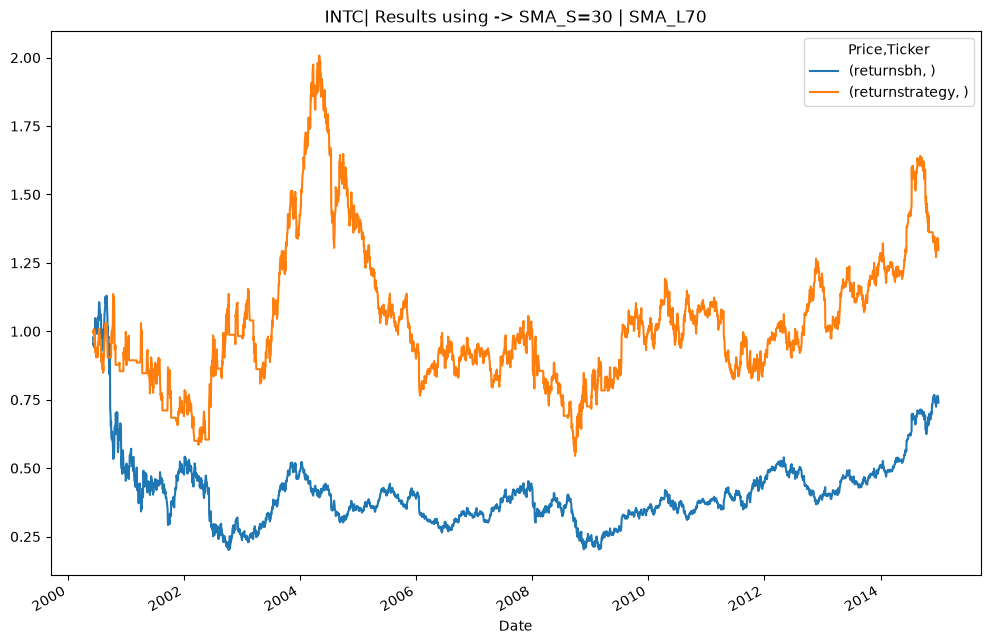

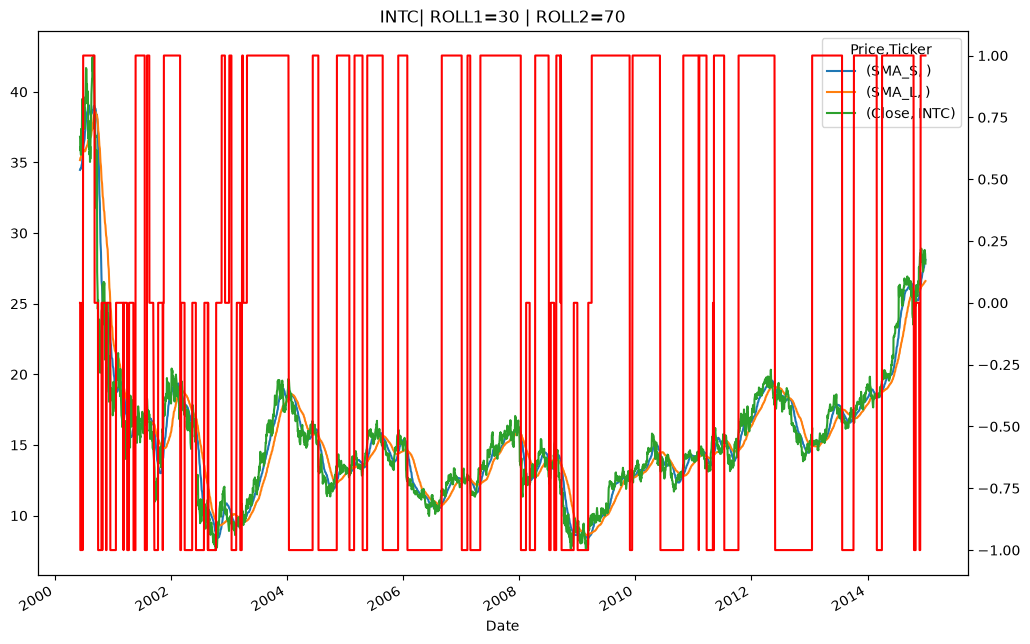

In [65]:
#no change at all so it wasnt activated as an indicator lets test at full data 
importlib.reload(SMA_t4)
test7=SMA_t4.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20,15
                           )

print(test7.test_result())
test7.plot_results()
test7.roll_graph()

In [66]:
#### yayyyyy workes !!! but we notice that the standard deviation is wayy too high 
# meaning very high risk model and might stumble or fail often as we see in graph in 2006 to 2012 it was near 1 fluctuating alot 
# so we can now add risk managing elements into the strategy 
#hypothesis risk comes from short term coming down we only did 30 or 20 as a thing but i want to add that if falling down continously for 8 days 
# and currently has positive  position then dont delay much in another way an or statement to exit thing

[*********************100%***********************]  1 of 1 completed


(np.float64(1.297064901671211), np.float64(0.33201524593037895), np.float64(0.55799))


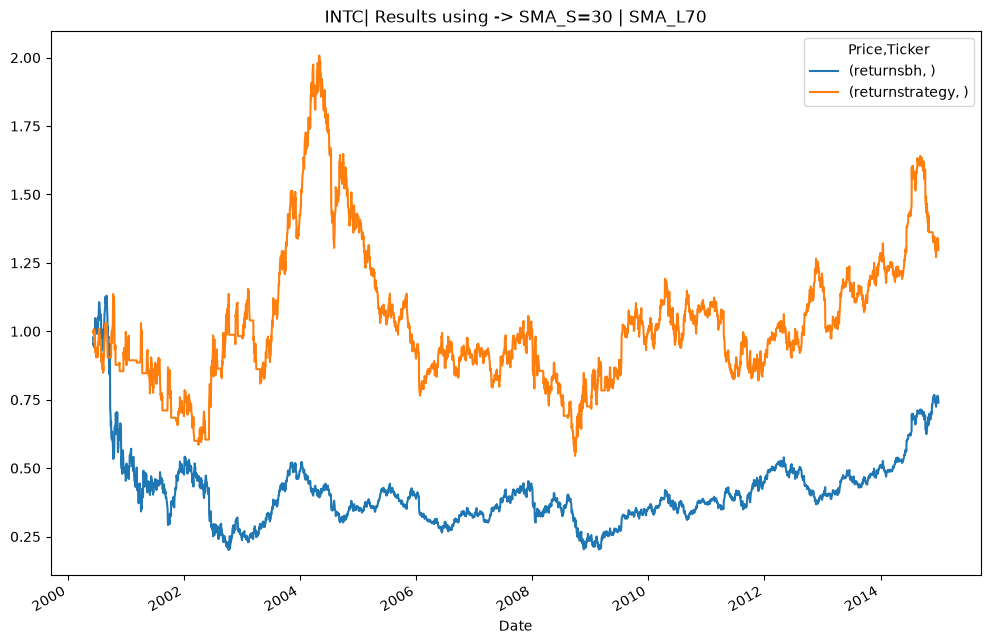

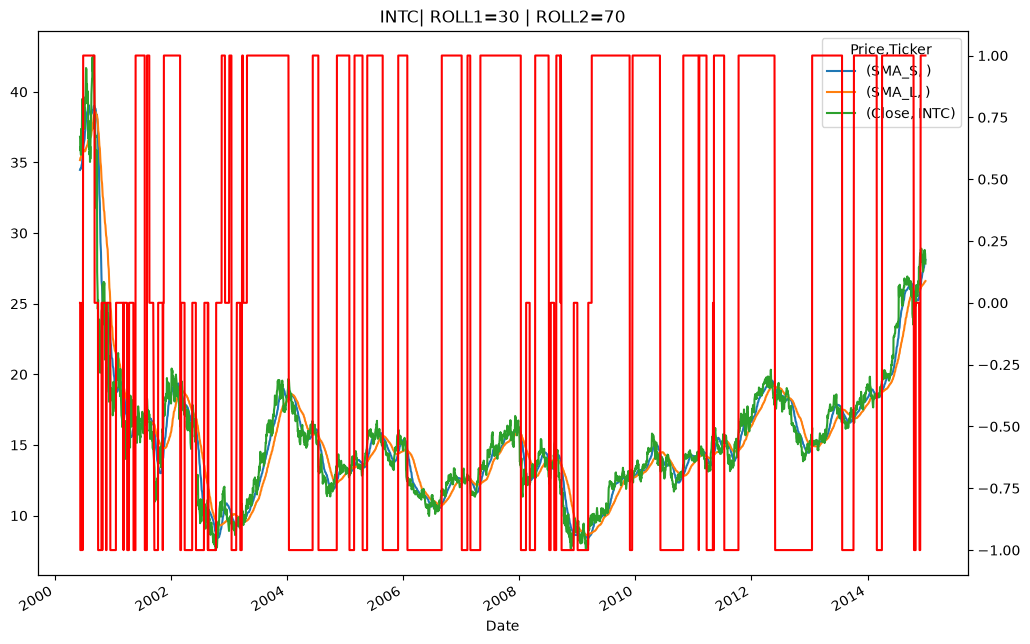

In [67]:
import SMA_test5 as SMA_t5
importlib.reload(SMA_t5)
test8=SMA_t5.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20,15
                           )

print(test8.test_result())
test8.plot_results()
test8.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.4910834322477693), np.float64(0.25450524725905954), np.float64(-0.410825))


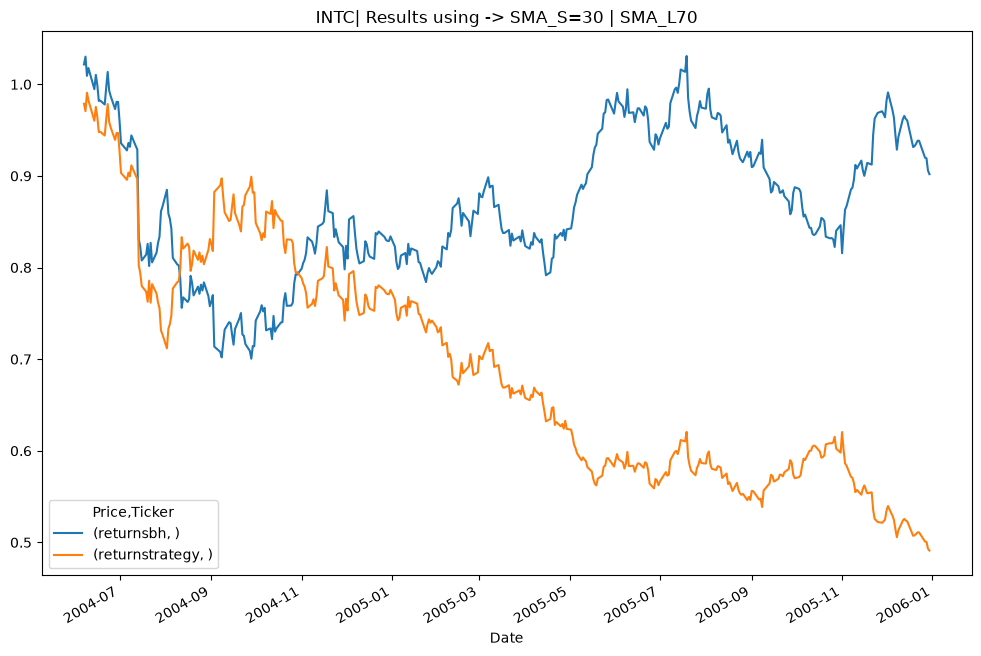

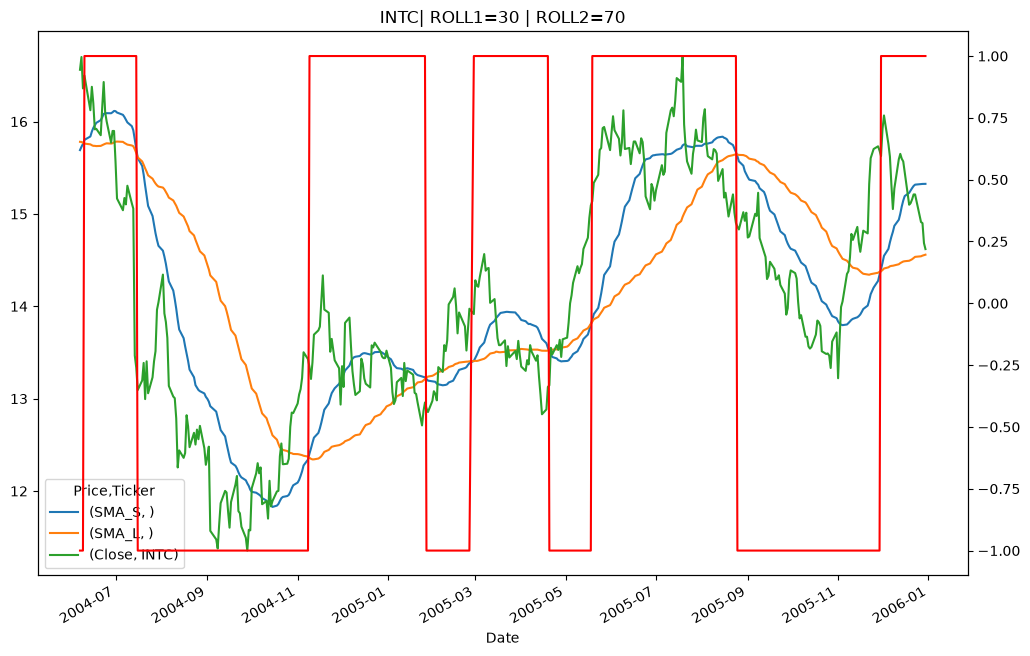

In [68]:
# i guess enemy was 2004 to 2006 period lets see that a bit 
import SMA_test5 as SMA_t5
importlib.reload(SMA_t5)
test8a=SMA_t5.SMABacktester("INTC",30,70,"2004-01-01","2006-01-01",20,15
                           )

print(test8a.test_result())
test8a.plot_results()
test8a.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.4910834322477693), np.float64(0.25450524725905954), np.float64(-0.410825))


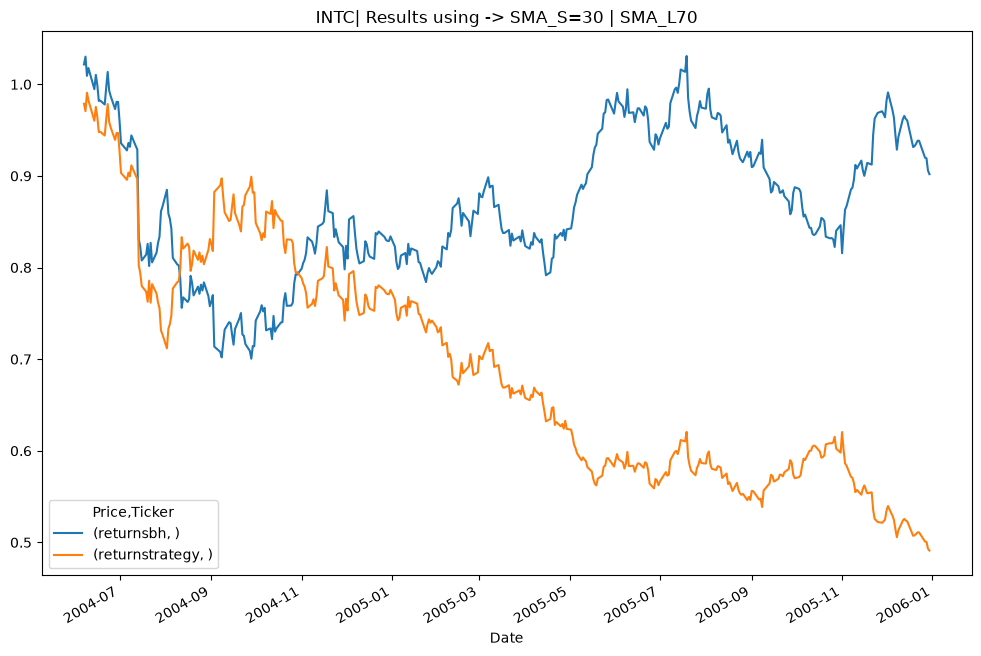

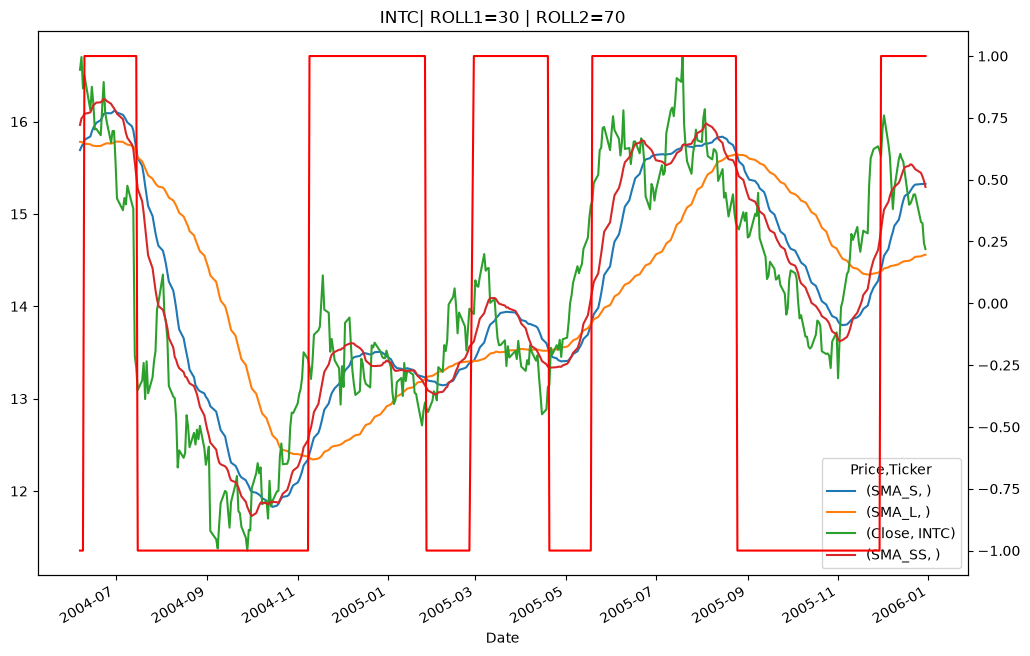

In [69]:
#ok a bizaare though but i can see market would have moved from 14 to 13 to 14 again and again in 2005
#so this clearly is happening when my sma_s is intersecting alot with current prive then suddenly it doesnt 
# so i think we should make sma_small_small as 10 day to smooth curve out then see some indicator 
import SMA_test6 as SMA_t6
importlib.reload(SMA_t6)
test9a=SMA_t6.SMABacktester("INTC",30,70,"2004-01-01","2006-01-01",20,15
                           )

print(test9a.test_result())
test9a.plot_results()
test9a.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(0.7560607772675425), np.float64(0.19531637017993567), np.float64(-0.145847))


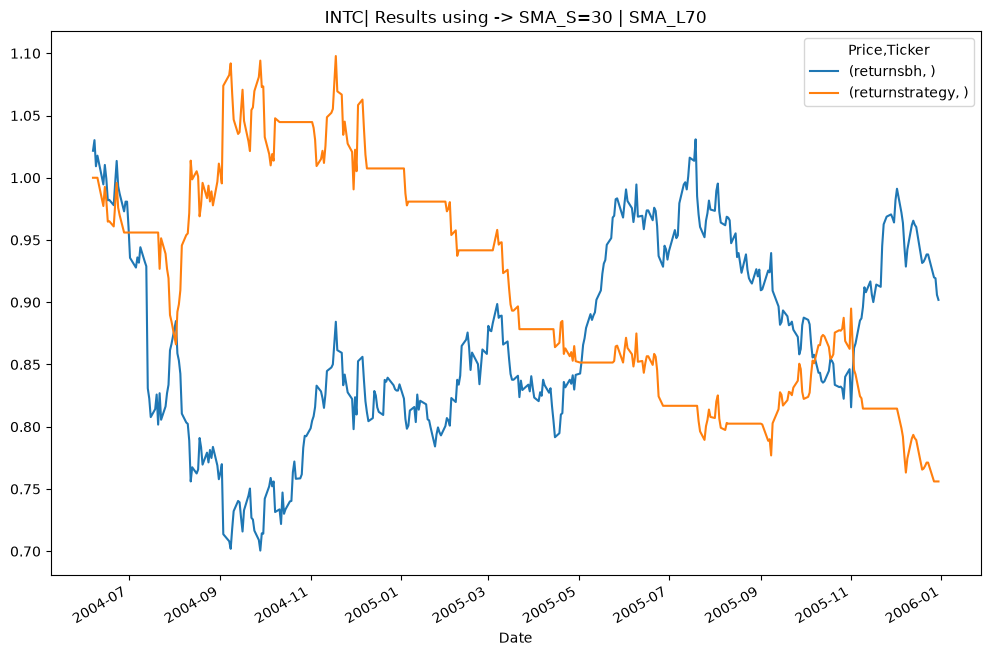

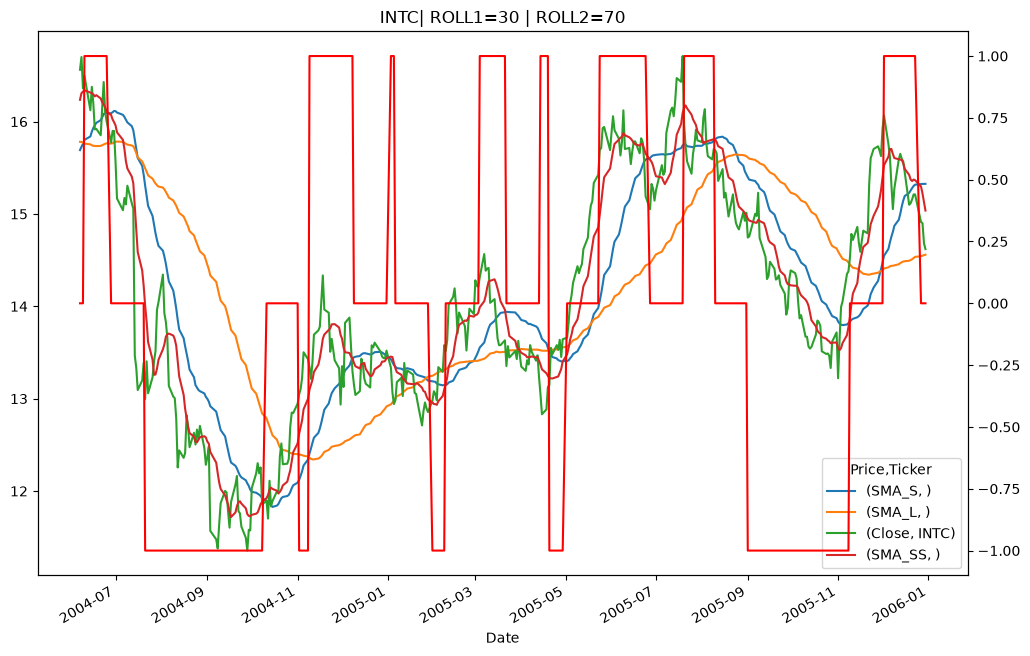

In [75]:
# ok maxima minima thing can also be seen via when then SMA_SS and SMA_S intersect each other and if sma_ss-sma_s goes from positive to negative 
# and some condition on SMA_L i dont know yet then indication maxima and reverse is minima so pull out and cooldown
import SMA_test7 as SMA_t7
importlib.reload(SMA_t7)
test10a=SMA_t7.SMABacktester("INTC",30,70,"2004-01-01","2006-01-01",20,15
                           )

print(test10a.test_result())
test10a.plot_results()
test10a.roll_graph()

[*********************100%***********************]  1 of 1 completed


(np.float64(1.10695308165738), np.float64(0.28829231741579914), np.float64(0.367878))


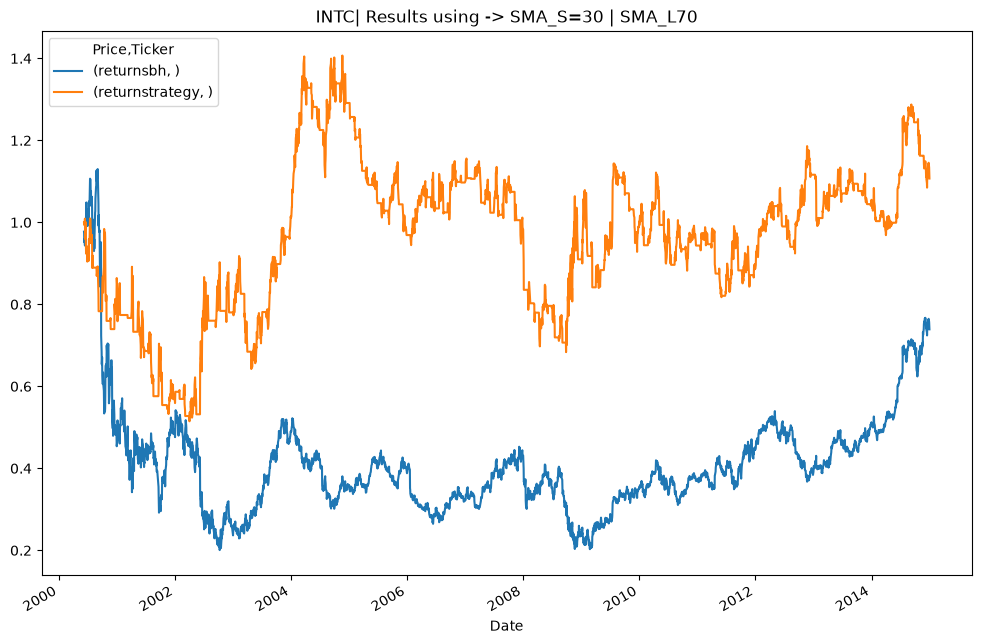

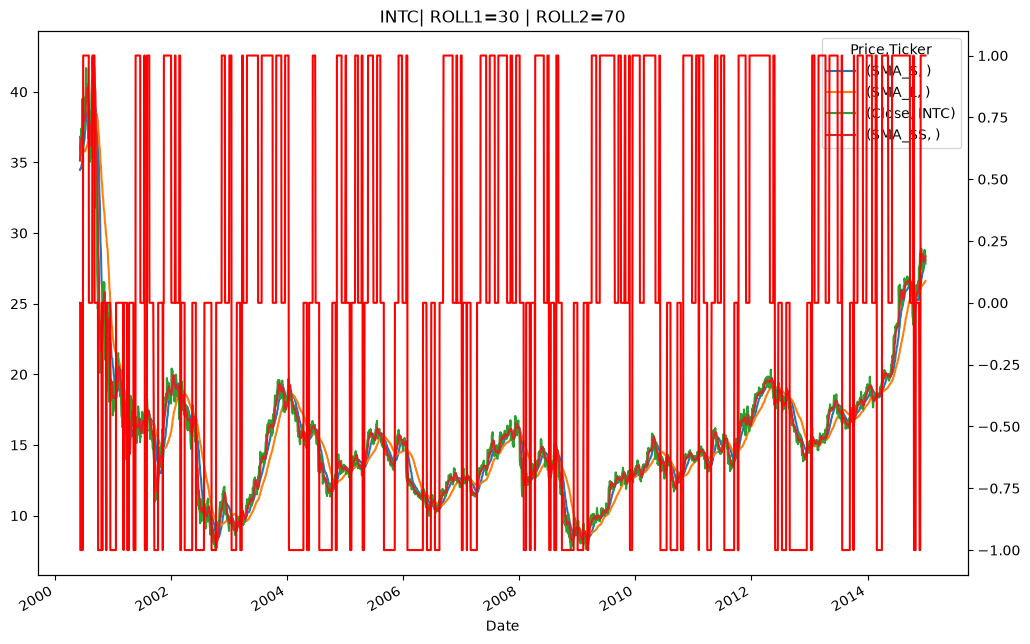

In [76]:
#ok not the best but much better i think lets try on final
import SMA_test7 as SMA_t7
importlib.reload(SMA_t7)
test10=SMA_t7.SMABacktester("INTC",30,70,"2000-01-01","2015-01-01",20,15
                           )

print(test10.test_result())
test10.plot_results()
test10.roll_graph()

In [ ]:
# ok standard deviation just got caried from 2006 to 2008 to 2008 to 2010
